# Circuito per realizzate una coppia entangled

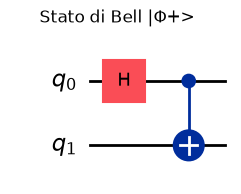

Statevector([0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.70710678+0.j],
            dims=(2, 2))
Statevector([0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.70710678+0.j],
            dims=(2, 2))


In [2]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
import matplotlib.pyplot as plt

# 1. Circuito per lo stato di Bell |Φ+>
qc = QuantumCircuit(2)
qc.h(0)        # superposizione sul qubit di controllo
qc.cx(0, 1)    # entanglement: controllo = 0, bersaglio = 1

# 2. Rendering grafico e salvataggio
fig = qc.draw(output='mpl', style='iqp')
fig.suptitle("Stato di Bell |Φ+>")
fig.savefig("bell_phi_plus.png", dpi=300, bbox_inches='tight')
display(fig)       # mostra l'immagine in Jupyter
plt.close(fig)

# 3. Verifica: vettore di stato finale
stato = Statevector.from_instruction(qc)
print(stato)       # atteso: [0.707+0j, 0, 0, 0.707+0j]
display(stato)

## Entanglement Swapping

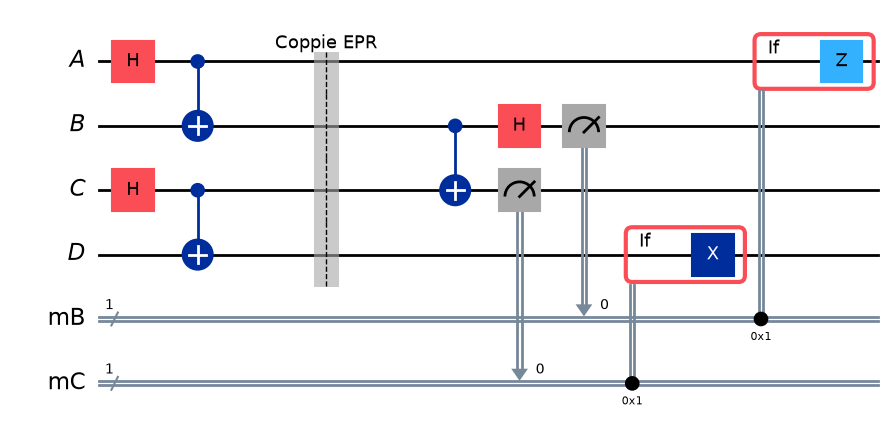

In [1]:
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister

A, B, C, D = 0, 1, 2, 3

qA, qB, qC, qD = (QuantumRegister(1, n) for n in "ABCD")
mB = ClassicalRegister(1, "mB")
mC = ClassicalRegister(1, "mC")
qc = QuantumCircuit(qA, qB, qC, qD, mB, mC)

# Prima coppia EPR (A,B)
qc.h(A); qc.cx(A, B)
# Seconda coppia EPR (C,D)
qc.h(C); qc.cx(C, D)

qc.barrier(label="Coppie EPR")

# Misura di Bell su B e C
qc.cx(B, C)
qc.h(B)

# Misure
qc.measure(B, mB)
qc.measure(C, mC)

# Correzioni condizionate (feed-forward classico)
with qc.if_test((mB, 1)):
    qc.z(A)
with qc.if_test((mC, 1)):
    qc.x(D)

fig = qc.draw(output="mpl", style="iqp")
# fig.savefig("entanglement_swapping_misure.png", dpi=300, bbox_inches="tight")
display(fig)
plt.close(fig)